# Group comparison of spike/event detection outputs — WT vs HET vs KO

This notebook collects every recording processed by the per-slice notebook (`*_analysis_REVISED.ipynb`),
builds one tidy table of slice-level metrics, and compares genotypes **at the animal level** 


## 1. Configuration

In [48]:
import os, re, json, glob, warnings, platform, datetime, itertools
from pathlib import Path

# Root folder that contains the WT / HET / KO folders written by the per-slice notebook.
ROOT = Path(r"D:\UMICH\PaperSubmission\Deep_Learning\Data\Spike Detection\Output")
OUT_DIR = ROOT / "Group_Comparison"           # all group-level outputs go here
FIG_DIR = OUT_DIR / "figures"

GENOTYPE_ORDER = ["WT", "HET", "KO"]          # order also defines the dosage trend for Jonckheere-Terpstra
REFERENCE_GENOTYPE = "WT"
GENOTYPE_COLORS = {"WT": "#4C72B0", "HET": "#DD8452", "KO": "#C44E52"}
CONDITIONS_TO_INCLUDE = None                  # e.g. ["Baseline"]; None = all, analysed separately per condition

# Optional metadata override. The per-slice notebook stores the animal as SAMPLE_ID; if SAMPLE_ID was not changed
# between mice (e.g. "Mouse_05" everywhere), animals cannot be told apart from the files. The notebook writes
# recording_metadata_TEMPLATE.csv on the first run: check/fix animal_id and slice_id there, save it as
# recording_metadata.csv in OUT_DIR, and re-run. That file then overrides the parsed values.
METADATA_OVERRIDE = OUT_DIR / "recording_metadata.csv"

# Which channels enter channel-derived metrics
MUA_LABEL = "MUA"                             # classification label written by the per-slice notebook

# Statistics
ALPHA = 0.05
N_PERMUTATIONS = 10000                        # Jonckheere-Terpstra permutation null
N_BOOTSTRAP = 5000                            # bootstrap CI of the animal-level genotype means
MIN_ANIMALS_PER_GROUP = 2                     # below this a genotype is dropped from a test (flagged)
RANDOM_SEED = 0

# Rate-like metrics are log10-transformed for the LMMs (right-skewed, multiplicative effects).
# Rank-based animal-level tests are unaffected by monotone transforms.
LOG_EPS = 1e-3

## 2. Imports and helpers

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy import stats
try:
    import statsmodels
    import statsmodels.formula.api as smf
    from statsmodels.tools.sm_exceptions import ConvergenceWarning
    HAVE_SM = True
except ImportError:
    HAVE_SM = False
    warnings.warn("statsmodels not installed -> mixed models skipped (pip install statsmodels).")

OUT_DIR.mkdir(parents=True, exist_ok=True); FIG_DIR.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(RANDOM_SEED)
WRITTEN = []

def save_csv(df, name):
    p = OUT_DIR / f"{name}.csv"; df.to_csv(p, index=False); WRITTEN.append(str(p)); print("  saved:", p.name)

def save_json(obj, name):
    p = OUT_DIR / f"{name}.json"
    p.write_text(json.dumps(obj, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)))
    WRITTEN.append(str(p)); print("  saved:", p.name)

def save_fig(fig, name):
    for ext in ("png", "svg"):
        p = FIG_DIR / f"{name}.{ext}"; fig.savefig(p, dpi=300, bbox_inches="tight"); WRITTEN.append(str(p))
    print("  saved figure:", name)

def safe_name(s):
    return re.sub(r"[^A-Za-z0-9_.-]+", "_", str(s))

## 3. Find every recording
Each per-slice output folder is identified by its `*_per_channel_summary.csv`. Genotype is taken from the top-level
folder (WT/HET/KO) and checked against the genotype written inside the files. Slice number is parsed from
`Slice<N>` in the recording name.

In [50]:
# =============================================================================
# 3. Find every recording and assign animal / slice
# -----------------------------------------------------------------------------
# Animal = recording DATE (one mouse per recording day). All slices with the same date and
# genotype are treated as slices from the same animal.
#   e.g. "2024-01-22_mPFC_Slice1_per_channel_summary.csv" -> animal "2024-01-22", slice "Slice1"
# The date is searched in the file name first, then the folder name, then the rest of the path.
# Accepted formats: 2024-01-22, 2024_01_22, 20240122.
# If two mice of the SAME genotype were recorded on the same day, they would be merged here;
# fix those rows with recording_metadata.csv (override, applied below).
# =============================================================================
DATE_RE  = re.compile(r"(?<!\d)(\d{4})[-_]?(\d{2})[-_]?(\d{2})(?!\d)")
SLICE_RE = re.compile(r"[Ss]lice[_\- ]?(\d+)")

def find_date(*texts):
    """First valid YYYY-MM-DD found in the given strings (in order), else None."""
    for t in texts:
        for m in DATE_RE.finditer(str(t)):
            y, mo, d = m.groups()
            if 1 <= int(mo) <= 12 and 1 <= int(d) <= 31:
                return f"{y}-{mo}-{d}"
    return None

def find_slice(*texts):
    for t in texts:
        m = SLICE_RE.search(str(t))
        if m:
            return f"Slice{int(m.group(1))}"
    return None

rows = []
for csv in sorted(ROOT.rglob("*_per_channel_summary.csv")):
    if OUT_DIR in csv.parents:                      # never read our own group outputs
        continue
    folder = csv.parent
    prefix = csv.name[: -len("_per_channel_summary.csv")]   # e.g. "2024-01-22_mPFC_Slice1"
    rel = folder.relative_to(ROOT).parts
    geno_folder = next((p for p in rel if p.upper() in GENOTYPE_ORDER), None)
    head = pd.read_csv(csv, nrows=1)

    date = find_date(prefix, folder.name, *rel)
    slc  = find_slice(prefix, folder.name, *rel)
    rows.append({
        "recording": f"{folder.name}/{prefix}",     # unique per file even if folder names repeat
        "folder": str(folder), "prefix": prefix,
        "genotype_folder": geno_folder.upper() if geno_folder else None,
        "genotype_file": str(head["genotype"].iloc[0]) if "genotype" in head else None,
        "condition": str(head["condition"].iloc[0]) if "condition" in head else "NA",
        "date": date,
        "animal_id": date if date else prefix,      # animal = recording day
        "slice_id": slc if slc else prefix,
    })
inv = pd.DataFrame(rows)
if inv.empty:
    raise FileNotFoundError(f"No *_per_channel_summary.csv found under {ROOT}")
inv["genotype"] = inv["genotype_folder"].fillna(inv["genotype_file"])

# ---- checks
no_date = inv[inv["date"].isna()]
if len(no_date):
    warnings.warn(f"{len(no_date)} recordings have no date in their name -> each is treated as its own animal:\n"
                  + "\n".join(no_date["prefix"]))
no_slice = inv[inv["slice_id"] == inv["prefix"]]
if len(no_slice):
    warnings.warn(f"{len(no_slice)} recordings have no 'Slice<N>' in their name:\n" + "\n".join(no_slice["prefix"]))
bad_geno = inv[inv["genotype_folder"].notna() & inv["genotype_file"].notna() &
               (inv["genotype_folder"] != inv["genotype_file"])]
if len(bad_geno):
    warnings.warn(f"{len(bad_geno)} recordings: genotype in folder != genotype in file (folder used):\n"
                  f"{bad_geno[['prefix','genotype_folder','genotype_file']]}")

# ---- template for manual correction, then optional override
inv[["recording", "prefix", "genotype", "condition", "date", "animal_id", "slice_id"]].to_csv(
    OUT_DIR / "recording_metadata_TEMPLATE.csv", index=False)
if METADATA_OVERRIDE.exists():
    ov = pd.read_csv(METADATA_OVERRIDE)
    cols = [c for c in ["genotype", "condition", "animal_id", "slice_id"] if c in ov]
    inv = inv.drop(columns=cols).merge(ov[["recording"] + cols], on="recording", how="left")
    print(f"Metadata override applied from {METADATA_OVERRIDE.name}")

# ---- keys: genotype is part of the animal key, so the same date in two genotypes = two different mice
inv["animal_key"] = inv["genotype"] + "|" + inv["animal_id"].astype(str)
inv["slice_key"]  = inv["animal_key"] + "|" + inv["slice_id"].astype(str) + "|" + inv["recording"]

same_day = inv.groupby("animal_id")["genotype"].nunique()
if (same_day > 1).any():
    print("Note: these dates occur in more than one genotype (counted as separate animals): "
          + ", ".join(same_day[same_day > 1].index))
dup_slice = inv.duplicated(["animal_key", "slice_id"], keep=False)
if dup_slice.any():
    print(f"Note: {dup_slice.sum()} recordings share animal + slice number (several recordings of one slice?); "
          "each is kept as its own slice-level observation and averaged within the animal.")

if CONDITIONS_TO_INCLUDE:
    inv = inv[inv["condition"].isin(CONDITIONS_TO_INCLUDE)]
inv = inv[inv["genotype"].isin(GENOTYPE_ORDER)].reset_index(drop=True)
save_csv(inv, "inventory")

# ---- show exactly how recordings were grouped so you can verify the animal count
animal_table = (inv.groupby(["condition", "genotype", "animal_id"])
                .agg(n_slices=("slice_key", "nunique"),
                     slices=("slice_id", lambda s: ", ".join(sorted(s.astype(str).unique()))))
                .reset_index())
save_csv(animal_table, "animal_slice_assignment")
print(animal_table.to_string(index=False))

summary_n = (inv.groupby(["condition", "genotype"])
             .agg(n_animals=("animal_key", "nunique"), n_slices=("slice_key", "nunique"))
             .reindex(GENOTYPE_ORDER, level=1))
print("\n", summary_n)

Note: these dates occur in more than one genotype (counted as separate animals): 2024-07-23
  saved: inventory.csv
  saved: animal_slice_assignment.csv
condition genotype  animal_id  n_slices                         slices
 Baseline      HET 2024-01-26         1                         Slice1
 Baseline      HET 2024-01-29         2                 Slice1, Slice4
 Baseline      HET 2024-06-04         3         Slice1, Slice2, Slice3
 Baseline      HET 2024-06-07         3         Slice1, Slice2, Slice3
 Baseline      HET 2024-06-12         3         Slice1, Slice2, Slice3
 Baseline      HET 2024-07-23         2                 Slice5, Slice6
 Baseline      HET 2024-07-24         1                         Slice1
 Baseline       KO 2024-01-22         2                 Slice1, Slice4
 Baseline       KO 2024-01-24         1                         Slice1
 Baseline       KO 2024-06-05         2                 Slice1, Slice4
 Baseline       KO 2024-06-10         1                         Sli

## 4. Detection-parameter consistency
Group comparisons are only valid if every recording was processed identically. Any parameter that differs between
recordings is listed and flagged.

In [31]:
def flatten(d, prefix=""):
    out = {}
    for k, v in d.items():
        key = f"{prefix}{k}"
        if isinstance(v, dict):
            out.update(flatten(v, key + "."))
        elif isinstance(v, list):
            out[key] = json.dumps(v)
        else:
            out[key] = v
    return out

prm_rows = []
for r in inv.itertuples():
    p = Path(r.folder) / f"{r.prefix}_detection_parameters.json"
    if p.exists():
        d = flatten(json.loads(p.read_text()))
        d["recording"] = r.recording
        prm_rows.append(d)
prm = pd.DataFrame(prm_rows)
check_cols = [c for c in prm.columns if c.startswith(("detection.", "validation.", "sufficiency.", "recording.sampling_rate"))]
varying = [c for c in check_cols if prm[c].astype(str).nunique() > 1]
cons = pd.DataFrame({"parameter": check_cols,
                     "n_distinct_values": [prm[c].astype(str).nunique() for c in check_cols],
                     "values": [" || ".join(sorted(prm[c].astype(str).unique())[:5]) for c in check_cols]})
save_csv(cons, "parameter_consistency")
if varying:
    warnings.warn("Detection parameters DIFFER between recordings: " + ", ".join(varying))
else:
    print(f"All {len(check_cols)} detection/validation/sufficiency parameters identical across {len(prm)} recordings.")
durations = prm.set_index("recording")["recording.duration_s"] if "recording.duration_s" in prm else pd.Series(dtype=float)

  saved: parameter_consistency.csv


C:\Users\sh2075\AppData\Local\Temp\ipykernel_59688\3488998228.py:28: UserWarning: Detection parameters DIFFER between recordings: validation.population_event_min_channels
  warnings.warn("Detection parameters DIFFER between recordings: " + ", ".join(varying))


## 5. Build slice-level metrics
For each recording, metrics are computed **per layer** (from the per-channel table), **per recording** (population
events, sampling sufficiency) and **per directed pair type** (connection density). Channel-derived rates and
waveform metrics are summarised by the *median across channels* (robust to a few very active electrodes), and
waveform/SNR metrics use MUA-classified channels only, so that noise-dominated channels do not dilute them.

In [51]:
METRIC_INFO = {   # metric -> (label, log-transform for LMM)
    "rate_hz_median_all":          ("Median event rate, all channels (Hz)", True),
    "rate_hz_median_MUA":          ("Median event rate, MUA channels (Hz)", True),
    "rate_hz_excl_pop_median_MUA": ("Median rate excl. population events, MUA (Hz)", True),
    "n_events_median_all":         ("Median events per channel (5 min)", True),
    "frac_MUA_channels":           ("Fraction of channels classified MUA", False),
    "threshold_x_noise_sd_median": ("Threshold (x noise SD), median", False),
    "trough_to_peak_ms_median_all":("Spike width, trough-to-peak (ms)", False),          # NEW
    "snr_median_all":              ("Spike SNR (peak / noise SD)", False),               # NEW
    "p2p_uV_median_all":           ("Spike amplitude, peak-to-peak (µV)", False),        # NEW
    "isi_violation_pct_median_all":("ISI violations < 1.5 ms (%)", False),               # NEW
    "snr_median_MUA":              ("Peak SNR, MUA channels", False),
    "trough_to_peak_ms_median_MUA":("Trough-to-peak width, MUA (ms)", False),
    "isi_violation_pct_median_MUA":("ISI violations < 1.5 ms, MUA (%)", False),
    "pop_event_fraction_median":   ("Fraction of events in population events", False),
    "pop_event_rate_hz":           ("Population-event rate (Hz)", True),
    "frac_pairs_adequate":         ("Directed pairs with E >= min (fraction)", False),
    "frac_triplets_adequate":      ("Triplets with all pairs adequate (fraction)", False),
    "median_expected_coincidences":("Median expected chance coincidences", True),
    "split_half_jaccard":          ("Split-half Jaccard of significant edges", False),
    "split_half_rho_z":            ("Split-half Spearman rho of z", False),
    "sig_edge_density":            ("Significant directed-edge density", False),
    "sig_edge_density_adequate":   ("Significant-edge density among adequate pairs", False),
}

def med(s):
    s = pd.Series(s).dropna(); return float(s.median()) if len(s) else np.nan

long_rows, chan_tables = [], []
for r in inv.itertuples():
    f = Path(r.folder); pre = r.prefix
    base = dict(recording=r.recording, condition=r.condition, genotype=r.genotype,
                animal_key=r.animal_key, animal_id=r.animal_id, slice_key=r.slice_key)
    ch = pd.read_csv(f / f"{pre}_per_channel_summary.csv")
    ch = ch.assign(**base)
    chan_tables.append(ch)
    # ---- per layer (and all layers pooled)
    for scope, g in list(ch.groupby("layer")) + [("All_layers", ch)]:
        mua = g[g["classification"] == MUA_LABEL]
        vals = {
            "rate_hz_median_all": med(g["rate_hz"]),
            "rate_hz_median_MUA": med(mua["rate_hz"]),
            "rate_hz_excl_pop_median_MUA": med(mua["rate_hz_excl_pop"]),
            "n_events_median_all": med(g["n_events"]),
            "frac_MUA_channels": float((g["classification"] == MUA_LABEL).mean()),
            "threshold_x_noise_sd_median": med(g["threshold_x_noise_sd"]),
            "trough_to_peak_ms_median_all": med(g["trough_to_peak_ms"]),           # NEW
            "snr_median_all": med(g["snr_peak"]),                                  # NEW
            "p2p_uV_median_all": med(g["median_wf_p2p_uV"]),                       # NEW
            "isi_violation_pct_median_all": med(g["isi_violation_pct"]),           # NEW
            "snr_median_MUA": med(mua["snr_peak"]),
            "trough_to_peak_ms_median_MUA": med(mua["trough_to_peak_ms"]),
            "isi_violation_pct_median_MUA": med(mua["isi_violation_pct"]),
            "pop_event_fraction_median": med(g["pop_event_fraction"]),
        }
        for k, v in vals.items():
            long_rows.append({**base, "scope": scope, "metric": k, "value": v})
    # ---- per recording
    dur = float(durations.get(r.recording, np.nan))
    pe = f / f"{pre}_population_events.csv"
    if pe.exists() and np.isfinite(dur):
        long_rows.append({**base, "scope": "Recording", "metric": "pop_event_rate_hz",
                          "value": len(pd.read_csv(pe)) / dur})
    sj = f / f"{pre}_sufficiency_summary.json"
    if sj.exists():
        s = json.loads(sj.read_text())
        for k_out, k_in in [("frac_pairs_adequate", "frac_pairs_expected_coinc_ge_min"),
                            ("frac_triplets_adequate", "frac_triplets_all_pairs_adequate"),
                            ("median_expected_coincidences", "median_expected_coincidences"),
                            ("split_half_jaccard", "split_half_jaccard_sig_edges"),
                            ("split_half_rho_z", "split_half_spearman_rho_z")]:
            long_rows.append({**base, "scope": "Recording", "metric": k_out, "value": s.get(k_in, np.nan)})
        long_rows.append({**base, "scope": "Recording", "metric": "verdict_sufficient",
                          "value": float(bool(s.get("verdict_sufficient", False)))})
    # ---- per directed pair type
    pp = f / f"{pre}_pairwise_sufficiency.csv"
    if pp.exists():
        pr = pd.read_csv(pp)
        for pt, g in list(pr.groupby("pair_type")) + [("All_pairs", pr)]:
            ga = g[g["adequate"]]
            long_rows.append({**base, "scope": pt, "metric": "sig_edge_density", "value": float(g["significant"].mean())})
            long_rows.append({**base, "scope": pt, "metric": "sig_edge_density_adequate",
                              "value": float(ga["significant"].mean()) if len(ga) else np.nan})

slice_long = pd.DataFrame(long_rows)
chan = pd.concat(chan_tables, ignore_index=True)
save_csv(slice_long, "slice_level_metrics_long")

animal_long = (slice_long.groupby(["condition", "genotype", "animal_key", "scope", "metric"], as_index=False)
               .agg(value=("value", "mean"), n_slices=("value", "count")))
save_csv(animal_long, "animal_level_metrics_long")
print(f"{slice_long['recording'].nunique()} recordings, {slice_long['animal_key'].nunique()} animals, "
      f"{len(chan)} channels loaded.")

  saved: slice_level_metrics_long.csv
  saved: animal_level_metrics_long.csv
44 recordings, 23 animals, 1604 channels loaded.


## 6. Statistics

**Animal level (primary).** For every condition × scope × metric: Kruskal–Wallis across genotypes; pairwise
Mann–Whitney U (exact for small n without ties) with Holm correction within the metric; Jonckheere–Terpstra trend
(permutation p, two-sided) for the WT→HET→KO dosage order; effect sizes vs WT (Hedges' g, Cliff's δ); bootstrap 95 % CI of
each genotype mean. Benjamini–Hochberg FDR (q) is applied across metrics within each condition × scope family.

**Slice level.** `value ~ C(genotype, Treatment('WT')) + (1 | animal)` (REML). Genotype effect: Wald χ² on the two
genotype coefficients. Rate-like metrics are log10-transformed. If an animal contributes only one slice the animal
variance is partly unidentifiable; the model still gives correct fixed-effect inference but convergence warnings are
recorded.
If the mixed model cannot be fitted reliably (no convergence or non-positive-definite Hessian, e.g. when a metric is
almost constant), the notebook falls back to OLS with cluster-robust standard errors by animal and says so in the
`model` column.

In [52]:
def holm(p):
    p = np.asarray(p, float); out = np.full_like(p, np.nan); ok = np.isfinite(p)
    if ok.sum() == 0: return out
    idx = np.argsort(p[ok]); m = ok.sum(); adj = np.empty(m)
    adj[idx] = np.minimum(1, np.maximum.accumulate((m - np.arange(m)) * p[ok][idx]))
    out[ok] = adj; return out

def bh(p):
    p = np.asarray(p, float); out = np.full_like(p, np.nan); ok = np.isfinite(p)
    if ok.sum() == 0: return out
    pv = p[ok]; m = len(pv); idx = np.argsort(pv)
    adj = np.minimum.accumulate((pv[idx] * m / np.arange(1, m + 1))[::-1])[::-1]
    res = np.empty(m); res[idx] = np.minimum(adj, 1); out[ok] = res; return out

def hedges_g(a, b):
    a, b = np.asarray(a), np.asarray(b); na, nb = len(a), len(b)
    if na < 2 or nb < 2: return np.nan
    sp = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    if sp == 0: return np.nan
    return (b.mean() - a.mean()) / sp * (1 - 3 / (4 * (na + nb) - 9))

def cliffs_delta(a, b):
    a, b = np.asarray(a), np.asarray(b)
    return float((np.sign(b[:, None] - a[None, :])).mean()) if len(a) and len(b) else np.nan

def jt_stat(groups):
    s = 0.0
    for i, j in itertools.combinations(range(len(groups)), 2):
        d = groups[j][None, :] - groups[i][:, None]
        s += (d > 0).sum() + 0.5 * (d == 0).sum()
    return s

def jonckheere(groups, n_perm=N_PERMUTATIONS):
    groups = [np.asarray(g, float) for g in groups]
    obs = jt_stat(groups); sizes = [len(g) for g in groups]; pooled = np.concatenate(groups)
    exp = sum(a * b for a, b in itertools.combinations(sizes, 2)) / 2
    cuts = np.cumsum(sizes)[:-1]; null = np.empty(n_perm)
    for k in range(n_perm):
        null[k] = jt_stat(np.split(rng.permutation(pooled), cuts))
    p = (np.sum(np.abs(null - exp) >= abs(obs - exp)) + 1) / (n_perm + 1)
    return obs, (obs - exp), p

def boot_ci(x, n=N_BOOTSTRAP):
    x = np.asarray(x, float)
    if len(x) < 2: return (np.nan, np.nan)
    bs = rng.choice(x, size=(n, len(x)), replace=True).mean(axis=1)
    return tuple(np.percentile(bs, [2.5, 97.5]))

desc_rows, omni_rows, pair_rows = [], [], []
for (cond, scope, metric), d in animal_long.groupby(["condition", "scope", "metric"]):
    d = d.dropna(subset=["value"])
    groups = {g: d.loc[d["genotype"] == g, "value"].values for g in GENOTYPE_ORDER}
    for g, v in groups.items():
        lo, hi = boot_ci(v)
        desc_rows.append({"condition": cond, "scope": scope, "metric": metric, "genotype": g, "n_animals": len(v),
                          "mean": np.mean(v) if len(v) else np.nan,
                          "sem": stats.sem(v) if len(v) > 1 else np.nan,
                          "median": np.median(v) if len(v) else np.nan,
                          "boot_ci_low": lo, "boot_ci_high": hi})
    tested = [g for g in GENOTYPE_ORDER if len(groups[g]) >= MIN_ANIMALS_PER_GROUP]
    row = {"condition": cond, "scope": scope, "metric": metric,
           **{f"n_{g}": len(groups[g]) for g in GENOTYPE_ORDER}, "groups_tested": "+".join(tested)}
    if len(tested) >= 2:
        vals = [groups[g] for g in tested]
        allv = np.concatenate(vals)
        if np.ptp(allv) > 0:
            if len(tested) >= 3:
                row["kruskal_H"], row["kruskal_p"] = stats.kruskal(*vals)
                row["JT_stat"], row["JT_minus_expected"], row["JT_p_perm"] = jonckheere(vals)
            pv, prs = [], []
            for a, b in itertools.combinations(tested, 2):
                u = stats.mannwhitneyu(groups[a], groups[b], alternative="two-sided")
                prs.append({"condition": cond, "scope": scope, "metric": metric, "group_a": a, "group_b": b,
                            "n_a": len(groups[a]), "n_b": len(groups[b]), "U": u.statistic, "p": u.pvalue,
                            "hedges_g_b_minus_a": hedges_g(groups[a], groups[b]),
                            "cliffs_delta_b_vs_a": cliffs_delta(groups[a], groups[b])})
                pv.append(u.pvalue)
            for pr_, ph in zip(prs, holm(pv)):
                pr_["p_holm"] = ph
            pair_rows += prs
            if len(tested) == 2:
                row["kruskal_p"] = prs[0]["p"]     # two groups only: report the MWU p as omnibus
    omni_rows.append(row)

desc = pd.DataFrame(desc_rows)
omni = pd.DataFrame(omni_rows)
pairs = pd.DataFrame(pair_rows)
for col in ("kruskal_p", "JT_p_perm"):
    if col in omni:
        omni[col.replace("_p", "_q_BH").replace("_perm", "")] = omni.groupby(["condition", "scope"])[col].transform(
            lambda s: pd.Series(bh(s.values), index=s.index))
omni["label"] = omni["metric"].map(lambda m: METRIC_INFO.get(m, (m,))[0])
save_csv(desc, "descriptives")
save_csv(omni, "stats_animal_level")
save_csv(pairs, "stats_animal_pairwise")

  saved: descriptives.csv
  saved: stats_animal_level.csv
  saved: stats_animal_pairwise.csv


In [58]:
for level in ["animal", "slice"]:
    d = pd.read_csv(OUT / f"{level}_level_raw.csv")
    print(f"\n=== {level.upper()} level: mean ± SEM ===")
    for col in ["rate_hz", "events_per_channel", "total_events"]:
        t = (d.groupby(["layer", "genotype"])[col]
               .agg(["mean", "sem", "count"])
               .reindex(GENOTYPES, level=1)
               .round(3))
        print(f"\n{col}")
        print(t.to_string())


=== ANIMAL level: mean ± SEM ===

rate_hz
                    mean    sem  count
layer   genotype                      
PrL23   WT        10.124  0.520      7
        HET        9.942  0.426      7
        KO         9.772  0.642      9
PrL23-5 WT        10.160  0.383      7
        HET        9.782  0.518      7
        KO         9.861  0.511      9
PrL5    WT        10.193  0.317      7
        HET        9.696  0.582      7
        KO         9.907  0.446      9

events_per_channel
                      mean      sem  count
layer   genotype                          
PrL23   WT        3048.842  155.896      7
        HET       2999.128  129.967      7
        KO        2948.609  195.515      9
PrL23-5 WT        3059.932  115.061      7
        HET       2950.618  156.915      7
        KO        2975.391  156.512      9
PrL5    WT        3070.130   95.405      7
        HET       2924.796  175.800      7
        KO        2989.192  137.005      9

total_events
                     

In [59]:
from scipy import stats

# spike width: channel -> slice mean -> animal mean (same averaging as the rates)
w_slice = (chan.groupby(['genotype', 'animal', 'slice', 'layer'])['trough_to_peak_ms']
               .mean().reset_index())
w_animal = w_slice.groupby(['genotype', 'animal', 'layer'])['trough_to_peak_ms'].mean().reset_index()

for layer in ['PrL23', 'PrL5']:
    d = w_animal[w_animal.layer == layer]
    groups = [d.loc[d.genotype == g, 'trough_to_peak_ms'] for g in GENOTYPES]
    F, p = stats.f_oneway(*groups)
    print(f"\n{layer}: F(2,{len(d) - 3}) = {F:.2f}, p = {p:.3f}")
    for g, x in zip(GENOTYPES, groups):
        print(f"  {g}: {x.mean():.3f} ± {x.sem():.3f} ms (n = {len(x)})")


PrL23: F(2,20) = 0.41, p = 0.666
  WT: 0.517 ± 0.063 ms (n = 7)
  HET: 0.509 ± 0.036 ms (n = 7)
  KO: 0.574 ± 0.062 ms (n = 9)

PrL5: F(2,20) = 0.87, p = 0.435
  WT: 0.509 ± 0.017 ms (n = 7)
  HET: 0.569 ± 0.043 ms (n = 7)
  KO: 0.567 ± 0.038 ms (n = 9)


In [53]:
# ---------------- slice level: LMM with random intercept per animal, plus naive slice-as-unit test
def fit_lmm(df, formula, groups, vc=None):
    """REML mixed model. Tries statsmodels' default optimiser chain first, then Powell and Nelder-Mead.
    A fit is accepted only if it converged AND its Hessian is positive definite (otherwise SEs/p are unreliable).
    Returns (result or None, short note)."""
    if not HAVE_SM: return None, "statsmodels missing"
    df = df.reset_index(drop=True)
    notes = []
    for method in (None, "powell", "nm"):
        tag = method or "default"
        with warnings.catch_warnings(record=True) as w:
            warnings.simplefilter("always")
            try:
                mod = smf.mixedlm(formula, df, groups=df[groups], vc_formula=vc)
                res = mod.fit(reml=True) if method is None else mod.fit(reml=True, method=method)
            except Exception as e:
                notes.append(f"{tag}: {type(e).__name__}"); continue
        msgs = sorted({str(x.message).split(".")[0][:70] for x in w if issubclass(x.category, ConvergenceWarning)})
        if res.converged and not any("Hessian" in m for m in msgs):
            boundary = any("boundary" in m for m in msgs)
            return res, (f"{tag}: ok" + ("; random-effect variance ~0 (boundary)" if boundary else ""))
        notes.append(f"{tag}: " + ("Hessian not positive definite" if any("Hessian" in m for m in msgs) else "not converged"))
    return None, " | ".join(notes)

def fit_model(df, formula, groups, vc=None):
    """LMM first; if it cannot be fitted reliably, fall back to OLS with cluster-robust (by animal) standard
    errors, which still respects the nesting of slices/channels within animals for the fixed-effect test."""
    res, note = fit_lmm(df, formula, groups, vc)
    if res is not None:
        return res, "LMM", note
    if not HAVE_SM:
        return None, "none", note
    try:
        d = df.reset_index(drop=True)
        res = smf.ols(formula, d).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(d[groups])[0]})
        return res, "OLS cluster-robust by animal", note + " -> fallback"
    except Exception as e:
        return None, "none", note + f" -> fallback failed: {type(e).__name__}"

def genotype_wald(res):
    fe = res.fe_params if hasattr(res, "fe_params") else res.params
    names = [n for n in fe.index if n.startswith("C(genotype")]
    if not names: return np.nan, np.nan, {}
    b = fe[names].values; V = res.cov_params().loc[names, names].values
    W = float(b @ np.linalg.pinv(V) @ b)
    coefs = {n.split("[T.")[-1].rstrip("]"): (fe[n], res.pvalues[n], *res.conf_int().loc[n].values)
             for n in names}
    return W, stats.chi2.sf(W, len(names)), coefs

ref = f"C(genotype, Treatment('{REFERENCE_GENOTYPE}'))"
lmm_rows, naive_rows = [], []
for (cond, scope, metric), d in slice_long.groupby(["condition", "scope", "metric"]):
    d = d.dropna(subset=["value"]).copy()
    if metric == "verdict_sufficient": continue          # binary; summarised separately
    present = [g for g in GENOTYPE_ORDER if (d["genotype"] == g).any()]
    if len(present) < 2 or d["value"].nunique() < 2: continue
    log_t = METRIC_INFO.get(metric, ("", False))[1]
    d["y"] = np.log10(d["value"] + LOG_EPS) if log_t else d["value"]
    # naive (pseudoreplicated) slice-level Kruskal-Wallis, for transparency only
    gv = [d.loc[d["genotype"] == g, "value"].values for g in present]
    naive_rows.append({"condition": cond, "scope": scope, "metric": metric,
                       **{f"n_slices_{g}": int((d['genotype'] == g).sum()) for g in GENOTYPE_ORDER},
                       "kruskal_p_slices_as_independent": stats.kruskal(*gv).pvalue if len(gv) > 1 else np.nan})
    res, model, note = fit_model(d, f"y ~ {ref}", "animal_key")
    row = {"condition": cond, "scope": scope, "metric": metric, "transform": "log10" if log_t else "none",
           "n_slices": len(d), "n_animals": d["animal_key"].nunique(), "model": model, "fit_note": note}
    if res is not None:
        W, p, coefs = genotype_wald(res)
        row.update({"wald_chi2_genotype": W, "p_genotype": p,
                    "animal_variance": float(res.cov_re.iloc[0, 0]) if model == "LMM" else np.nan,
                    "residual_variance": float(res.scale)})
        for g, (b, pb, lo, hi) in coefs.items():
            row.update({f"{g}_vs_{REFERENCE_GENOTYPE}_beta": b, f"{g}_p": pb, f"{g}_ci_low": lo, f"{g}_ci_high": hi})
    lmm_rows.append(row)

lmm = pd.DataFrame(lmm_rows)
if "p_genotype" in lmm:
    lmm["q_BH_genotype"] = lmm.groupby(["condition", "scope"])["p_genotype"].transform(
        lambda s: pd.Series(bh(s.values), index=s.index))
naive = pd.DataFrame(naive_rows)
save_csv(lmm, "stats_slice_level_LMM")
save_csv(naive, "stats_slice_naive")

  saved: stats_slice_level_LMM.csv
  saved: stats_slice_naive.csv


In [54]:
# ---------------- channel level (supplementary): random intercepts for animal and for slice within animal
CHANNEL_METRICS = {"rate_hz": True, "threshold_x_noise_sd": False, "snr_peak": False}
chan_rows = []
for cond, dc in chan.groupby("condition"):
    for scope, dl in list(dc.groupby("layer")) + [("All_layers", dc)]:
        for subset, ds in [("all_channels", dl), ("MUA_only", dl[dl["classification"] == MUA_LABEL])]:
            for metric, log_t in CHANNEL_METRICS.items():
                d = ds.dropna(subset=[metric]).copy()
                if d["genotype"].nunique() < 2: continue
                d["y"] = np.log10(d[metric] + LOG_EPS) if log_t else d[metric]
                res, model, note = fit_model(d, f"y ~ {ref}", "animal_key", vc={"slice": "0 + C(slice_key)"})
                row = {"condition": cond, "scope": scope, "channels": subset, "metric": metric,
                       "transform": "log10" if log_t else "none", "n_channels": len(d),
                       "n_slices": d["slice_key"].nunique(), "n_animals": d["animal_key"].nunique(),
                       "model": model, "fit_note": note}
                if res is not None:
                    W, p, coefs = genotype_wald(res)
                    row.update({"wald_chi2_genotype": W, "p_genotype": p})
                    for g, (b, pb, lo, hi) in coefs.items():
                        row.update({f"{g}_vs_{REFERENCE_GENOTYPE}_beta": b, f"{g}_p": pb})
                chan_rows.append(row)
chan_lmm = pd.DataFrame(chan_rows)
save_csv(chan_lmm, "stats_channel_level_LMM")

# ---------------- sufficiency verdict by genotype (per slice and per animal)
suf = slice_long[slice_long["metric"] == "verdict_sufficient"]
suf_tab = (suf.groupby(["condition", "genotype"])
           .agg(n_slices=("value", "size"), n_slices_sufficient=("value", "sum"),
                n_animals=("animal_key", "nunique"))
           .reset_index())
anim_suf = suf.groupby(["condition", "genotype", "animal_key"])["value"].mean().reset_index()
suf_tab = suf_tab.merge(anim_suf.groupby(["condition", "genotype"])["value"].mean()
                        .rename("mean_fraction_sufficient_per_animal").reset_index(), on=["condition", "genotype"])
save_csv(suf_tab, "sufficiency_by_genotype")
print(suf_tab)

  saved: stats_channel_level_LMM.csv
  saved: sufficiency_by_genotype.csv
  condition genotype  n_slices  n_slices_sufficient  n_animals  \
0  Baseline      HET        15                  0.0          7   
1  Baseline       KO        14                  0.0          9   
2  Baseline       WT        15                  0.0          7   

   mean_fraction_sufficient_per_animal  
0                                  0.0  
1                                  0.0  
2                                  0.0  


## 7. Figures
**SuperPlots** (Lord et al., 2020, *J Cell Biol*): small dots = slices (coloured by animal within each genotype),
large outlined dots = animal means, bar = mean ± SEM of animals. The p-values printed on each panel are
**animal-level** (Kruskal–Wallis, and Jonckheere–Terpstra trend) and slice-level LMM.

  saved figure: superplot_Baseline_rate_hz_median_all


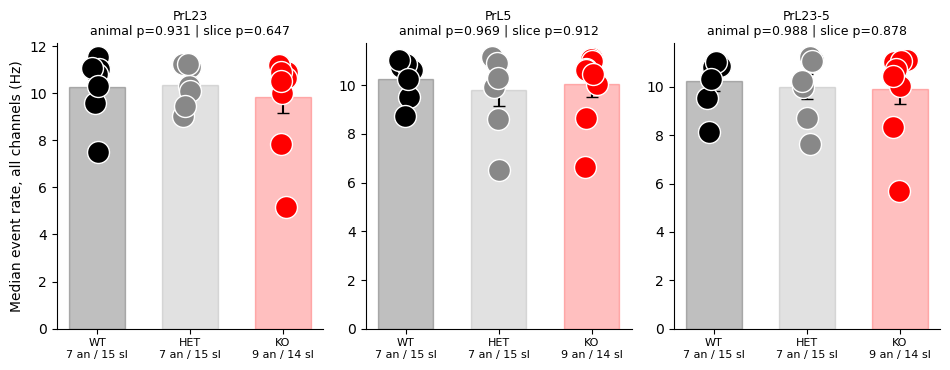

  saved figure: superplot_Baseline_n_events_median_all


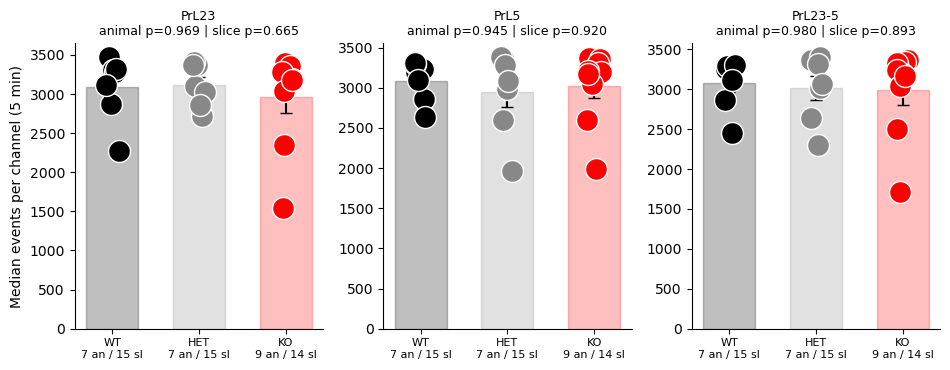

  saved figure: superplot_Baseline_frac_MUA_channels


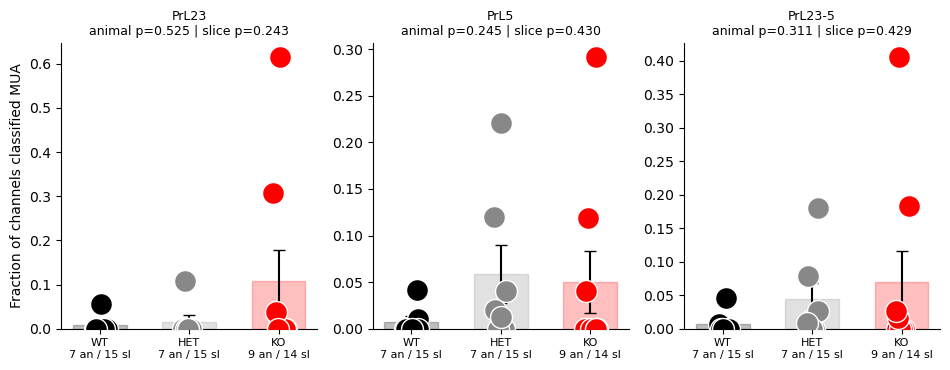

  saved figure: superplot_Baseline_threshold_x_noise_sd_median


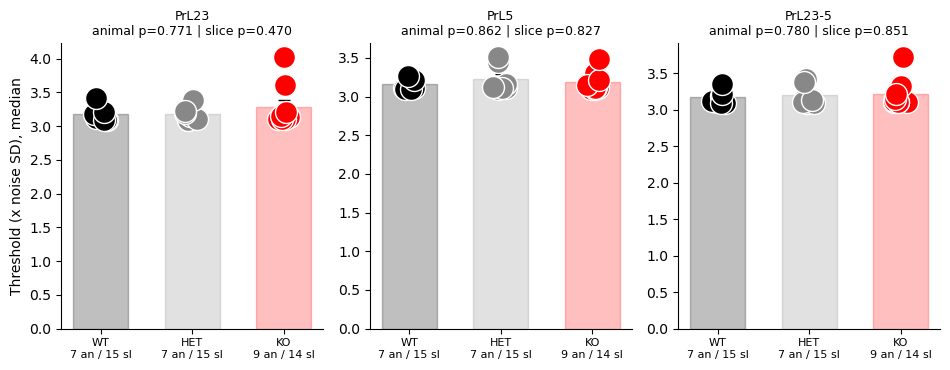

  saved figure: superplot_Baseline_trough_to_peak_ms_median_all


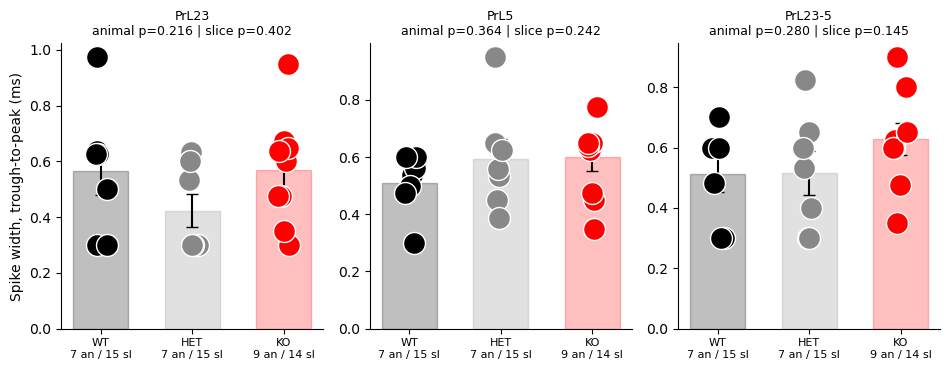

  saved figure: superplot_Baseline_snr_median_all


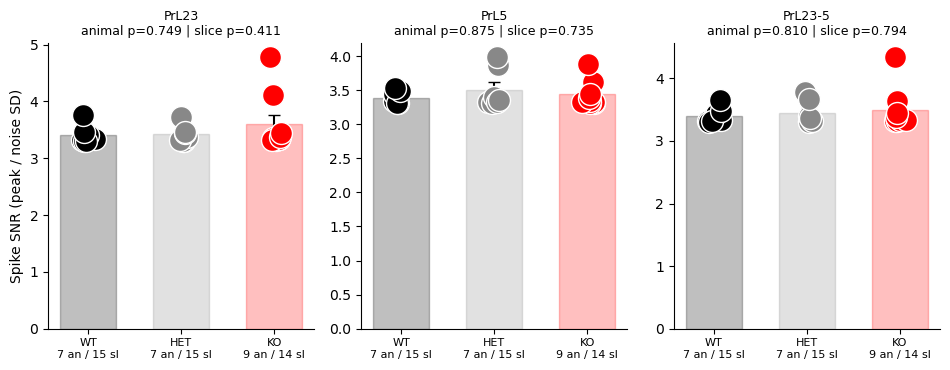

  saved figure: superplot_Baseline_p2p_uV_median_all


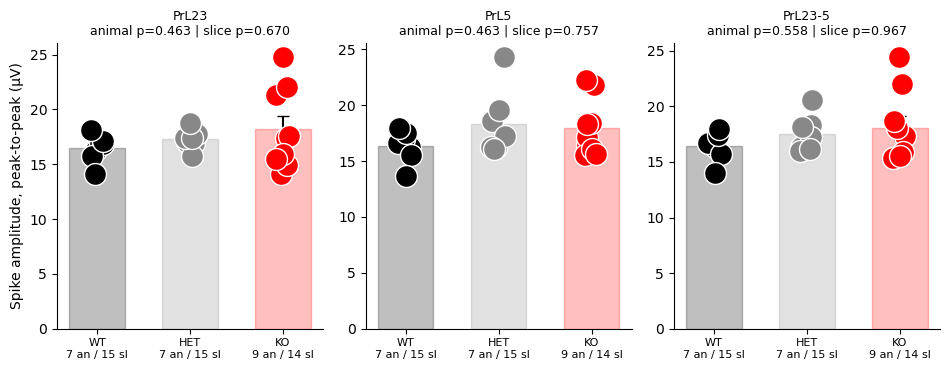

  saved figure: superplot_Baseline_isi_violation_pct_median_all


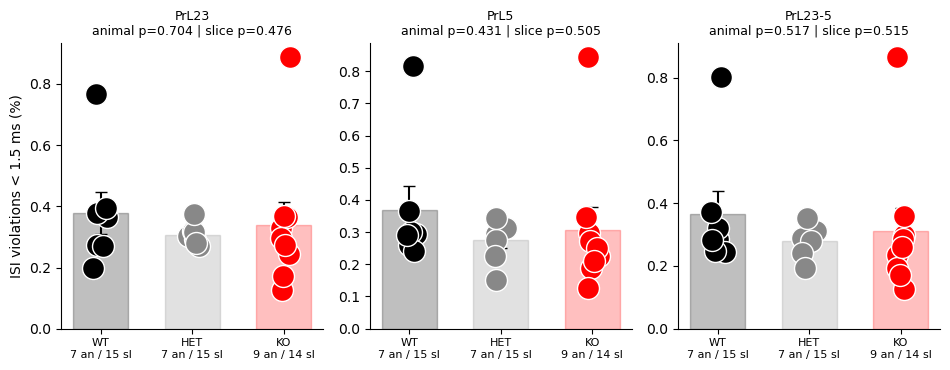

  saved figure: superplot_Baseline_pop_event_fraction_median


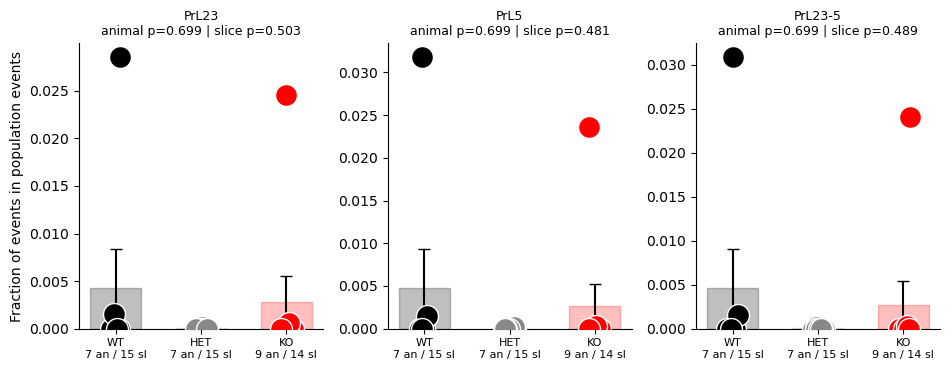

  saved figure: superplot_Baseline_pop_event_rate_hz


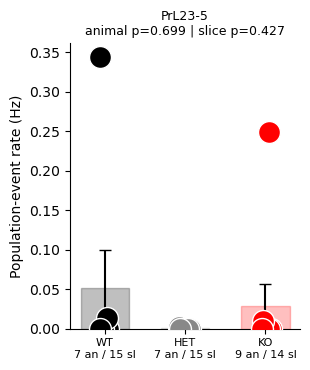

  saved figure: superplot_Baseline_frac_pairs_adequate


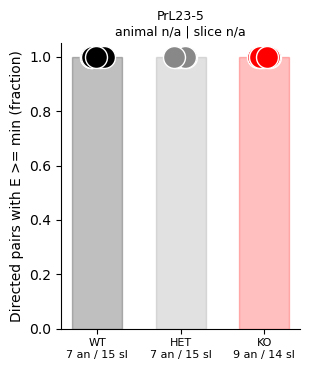

  saved figure: superplot_Baseline_frac_triplets_adequate


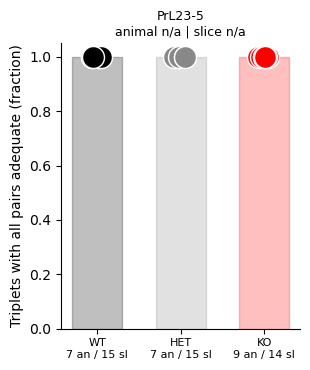

  saved figure: superplot_Baseline_median_expected_coincidences


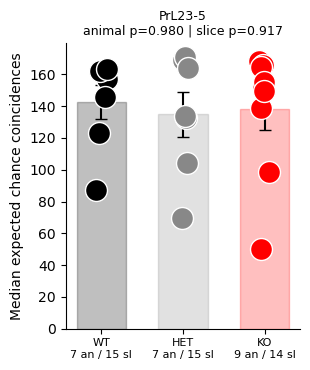

  NOTE split_half_jaccard | PrL23-5 | WT: 6 of 7 animals have data
  saved figure: superplot_Baseline_split_half_jaccard


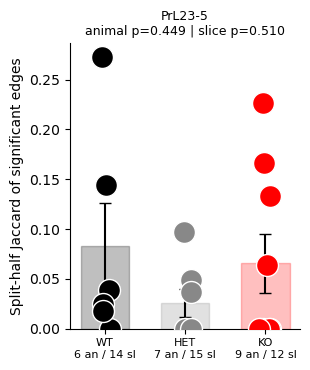

  saved figure: superplot_Baseline_split_half_rho_z


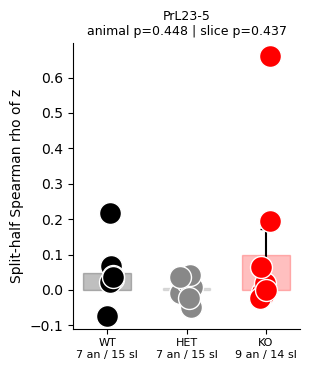

  saved figure: superplot_Baseline_sig_edge_density


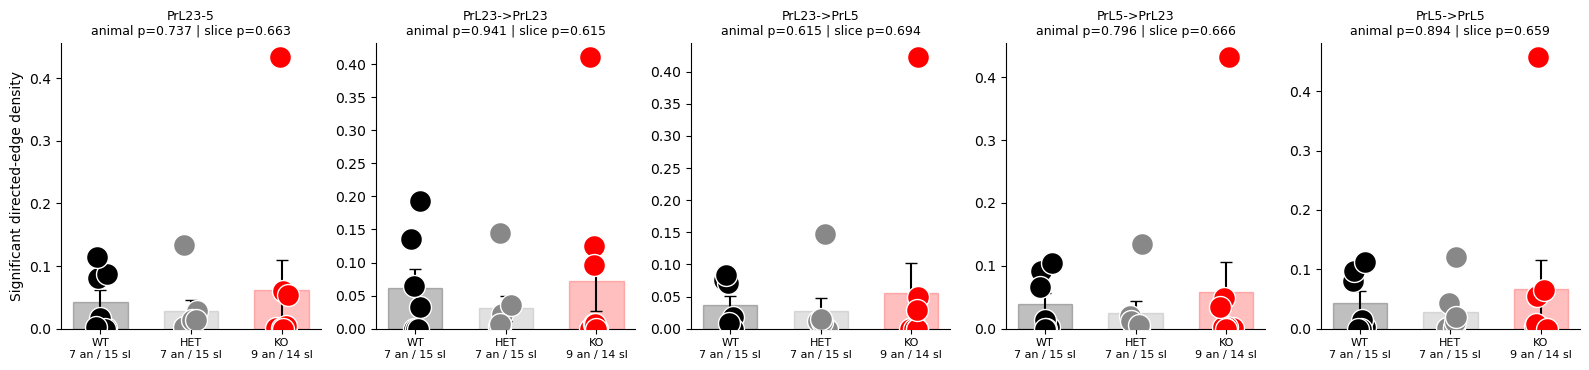

  saved figure: superplot_Baseline_sig_edge_density_adequate


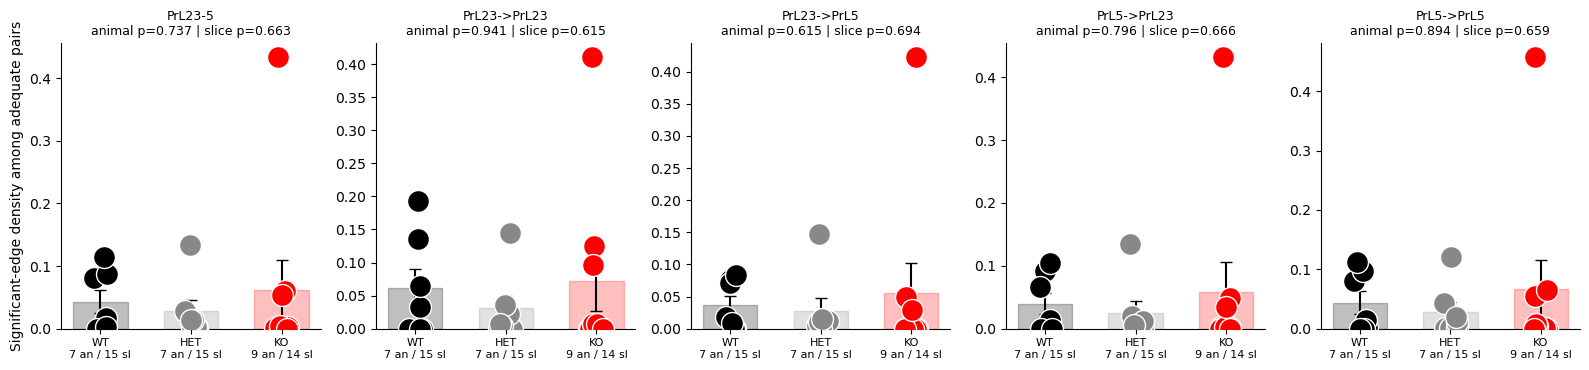

In [55]:
# ---- figure style
Z_SCORE = False      # False = raw values | True = z-score every metric against WT animals
GENOTYPE_COLORS = {'WT': '#000000', 'HET': '#888888', 'KO': '#FF0000'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})

# only metrics that exist for EVERY animal (the *_MUA metrics drop animals without MUA channels)
PLOT_METRICS = {m: v for m, v in METRIC_INFO.items() if not m.endswith('_MUA')}
SCOPE_ORDER = ['PrL23', 'PrL5', 'PrL23-5']
n_total = inv.groupby('genotype')['animal_key'].nunique()      # all animals per genotype

def nice(scope):
    """File scope names -> PrL23 / PrL5 / PrL23-5."""
    for old, new in [('PrL_L23', 'PrL23'), ('PrL_L5', 'PrL5'), ('All_layers', 'PrL23-5'),
                     ('Recording', 'PrL23-5'), ('All_pairs', 'PrL23-5')]:
        scope = scope.replace(old, new)
    return scope

def fmt_p(p):
    return 'n/a' if p is None or not np.isfinite(p) else ('p<0.001' if p < 0.001 else f'p={p:.3f}')

def superplot(ax, cond, scope, metric):
    ds = slice_long[(slice_long.condition == cond) & (slice_long.scope == scope) & (slice_long.metric == metric)].dropna(subset=['value'])
    da = animal_long[(animal_long.condition == cond) & (animal_long.scope == scope) & (animal_long.metric == metric)].dropna(subset=['value'])

    if Z_SCORE:                                   # same WT reference for animal and slice dots
        wt = da.loc[da.genotype == 'WT', 'value']
        if wt.std() > 0:
            da = da.assign(value=(da.value - wt.mean()) / wt.std())
            ds = ds.assign(value=(ds.value - wt.mean()) / wt.std())
        ax.axhline(0, color='k', ls='--', lw=0.8)

    ticks = []
    for i, g in enumerate(GENOTYPE_ORDER):
        c = GENOTYPE_COLORS[g]
        a = da.loc[da.genotype == g, 'value']
        s = ds.loc[ds.genotype == g, 'value']
        ax.bar(i, a.mean(), yerr=a.sem(), width=0.6, color=c, alpha=0.25, edgecolor=c, capsize=4)
        # ax.scatter(i + rng.uniform(-0.15, 0.15, len(s)), s, s=20, facecolors='none', edgecolors=c)   # slices
        ax.scatter(i + rng.uniform(-0.08, 0.08, len(a)), a, s=250, color=c, zorder=3, edgecolors='w')                  # animals
        ticks.append(f'{g}\n{len(a)} an / {len(s)} sl')
        if len(a) < n_total.get(g, 0):
            print(f'  NOTE {metric} | {nice(scope)} | {g}: {len(a)} of {n_total[g]} animals have data')

    ax.set_xticks(range(len(GENOTYPE_ORDER)))
    ax.set_xticklabels(ticks, fontsize=8)

    o = omni[(omni.condition == cond) & (omni.scope == scope) & (omni.metric == metric)]
    l = lmm[(lmm.condition == cond) & (lmm.scope == scope) & (lmm.metric == metric)] if len(lmm) else pd.DataFrame()
    kp = o['kruskal_p'].iloc[0] if len(o) and 'kruskal_p' in o else np.nan
    lp = l['p_genotype'].iloc[0] if len(l) and 'p_genotype' in l else np.nan
    ax.set_title(f'{nice(scope)}\nanimal {fmt_p(kp)} | slice {fmt_p(lp)}', fontsize=9)

for cond in sorted(slice_long['condition'].unique()):
    for metric, (label, _) in PLOT_METRICS.items():
        scopes = slice_long.loc[(slice_long.condition == cond) & (slice_long.metric == metric), 'scope'].unique()
        scopes = sorted(scopes, key=lambda s: SCOPE_ORDER.index(nice(s)) if nice(s) in SCOPE_ORDER else 99)
        if not scopes:
            continue
        fig, axs = plt.subplots(1, len(scopes), figsize=(3.2 * len(scopes), 3.8), squeeze=False)
        for ax, sc in zip(axs[0], scopes):
            superplot(ax, cond, sc, metric)
        axs[0, 0].set_ylabel(f'{label}\n(z-score vs WT)' if Z_SCORE else label)
        fig.tight_layout()
        suffix = '_z' if Z_SCORE else ''
        save_fig(fig, f'superplot_{safe_name(cond)}_{metric}{suffix}')
        plt.show(); plt.close(fig)

## 8. Report, parameters, manifest
The report states the n of animals and slices, the parameter-consistency check, every animal-level result with
q < 0.05, and — importantly for the motif analysis — whether **event counts or sampling sufficiency differ between
genotypes**. If they do, genotype differences in motif counts could partly reflect how many events were available,
which is why motif counts should be surrogate-normalised and this comparison reported alongside them.

In [ ]:
try:
    suf_md = suf_tab.to_markdown(index=False)      # needs the 'tabulate' package
except ImportError:
    suf_md = "```\n" + suf_tab.to_string(index=False) + "\n```"
lines = [f"# Group comparison report — generated {datetime.datetime.now():%Y-%m-%d %H:%M}", ""]
lines += ["## Sample sizes", "", "| Condition | Genotype | Animals | Slices |", "|---|---|---|---|"]
for (c, g), r_ in summary_n.iterrows():
    lines.append(f"| {c} | {g} | {int(r_.n_animals) if pd.notna(r_.n_animals) else 0} | {int(r_.n_slices) if pd.notna(r_.n_slices) else 0} |")
lines += ["", "## Processing consistency", "",
          ("All detection, validation and sufficiency parameters were identical across recordings."
           if not varying else "**Parameters differing between recordings:** " + ", ".join(varying)), ""]
if (dup > 1).any():
    lines += ["**WARNING:** identical animal IDs found in more than one genotype; animal-level statistics are not valid "
              "until animal_id is corrected in recording_metadata.csv.", ""]

lines += ["## Animal-level results (primary)", "",
          "Kruskal–Wallis across genotypes, BH-FDR within each condition × scope. JT = Jonckheere–Terpstra WT→HET→KO trend.", "",
          "| Condition | Scope | Metric | n WT/HET/KO | KW p | KW q | JT p | slice LMM p |", "|---|---|---|---|---|---|---|---|"]
om = omni.copy()
if len(lmm) and "p_genotype" in lmm:
    om = om.merge(lmm[["condition", "scope", "metric", "p_genotype"]], on=["condition", "scope", "metric"], how="left")
else:
    om["p_genotype"] = np.nan
for col in ("kruskal_p", "kruskal_q_BH", "JT_p_perm"):
    if col not in om: om[col] = np.nan
om = om.sort_values(["condition", "scope", "kruskal_p"])
for r_ in om.itertuples():
    ns = "/".join(str(getattr(r_, f"n_{g}")) for g in GENOTYPE_ORDER)
    lines.append(f"| {r_.condition} | {r_.scope} | {r_.label} | {ns} | {fmt_p(r_.kruskal_p)} | {fmt_p(r_.kruskal_q_BH)} | "
                 f"{fmt_p(r_.JT_p_perm)} | {fmt_p(r_.p_genotype)} |")

sig = om[om["kruskal_q_BH"] < ALPHA]
lines += ["", f"**{len(sig)} animal-level tests with q < {ALPHA}.**", ""]
conf = om[om["metric"].isin(["rate_hz_median_all", "n_events_median_all", "frac_pairs_adequate", "frac_triplets_adequate"])
          & om["scope"].isin(["All_layers", "Recording"])]
lines += ["## Event-count confound check for the motif analysis", ""]
for r_ in conf.itertuples():
    lines.append(f"* {r_.condition} — {r_.label}: animal-level KW {fmt_p(r_.kruskal_p)}, trend {fmt_p(r_.JT_p_perm)}")
lines += ["", "If any of these differ between genotypes, motif and connectivity differences must be interpreted "
          "relative to surrogate/null models that preserve each channel's event count.", "",
          "## Sufficiency verdict by genotype", "", suf_md,
          "", "## Statistical methods (for the manuscript)", "",
          f"Animals were the unit of replication. Slice-level metrics were averaged within each animal and genotypes were "
          f"compared with Kruskal–Wallis tests followed by two-sided Mann–Whitney U tests with Holm correction; a monotonic "
          f"gene-dosage trend ({' → '.join(GENOTYPE_ORDER)}) was tested with the Jonckheere–Terpstra test "
          f"({N_PERMUTATIONS} permutations). Benjamini–Hochberg FDR was applied across metrics within each layer/scope. "
          f"Effect sizes are Hedges' g and Cliff's δ relative to {REFERENCE_GENOTYPE}, with bootstrap 95 % CIs "
          f"({N_BOOTSTRAP} resamples) of genotype means. Slice-level data were additionally analysed with linear "
          f"mixed-effects models (genotype fixed effect, random intercept per animal; REML; Wald χ² test of genotype), "
          f"and channel-level metrics with random intercepts for animal and slice within animal. Rate-like variables were "
          f"log10-transformed for mixed models. Analyses used Python {platform.python_version()}, SciPy {scipy.__version__}"
          + (f", statsmodels {statsmodels.__version__}." if HAVE_SM else ".")]
p = OUT_DIR / "GROUP_REPORT.md"; p.write_text("\n".join(lines), encoding="utf-8"); WRITTEN.append(str(p))
print("\n".join(lines[:40]))

save_json({"root": str(ROOT), "genotype_order": GENOTYPE_ORDER, "reference": REFERENCE_GENOTYPE,
           "conditions": CONDITIONS_TO_INCLUDE, "alpha": ALPHA, "n_permutations": N_PERMUTATIONS,
           "n_bootstrap": N_BOOTSTRAP, "min_animals_per_group": MIN_ANIMALS_PER_GROUP, "seed": RANDOM_SEED,
           "log_eps": LOG_EPS, "metric_info": METRIC_INFO, "metadata_override_used": METADATA_OVERRIDE.exists(),
           "software": {"python": platform.python_version(), "numpy": np.__version__, "scipy": scipy.__version__,
                        "pandas": pd.__version__, "statsmodels": statsmodels.__version__ if HAVE_SM else None}},
          "analysis_parameters")
p = OUT_DIR / "run_manifest.json"; p.write_text(json.dumps({"files": WRITTEN}, indent=2))
print(f"\nDone: {len(WRITTEN) + 1} files in {OUT_DIR}")

In [ ]:
import re
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

# ================= settings
ROOT = Path(r"D:\UMICH\PaperSubmission\Deep_Learning\Data\Spike Detection\Output")
OUT = ROOT / "Waveforms_Rasters"
OUT.mkdir(exist_ok=True)

GENOTYPES = ['WT', 'HET', 'KO']
GENOTYPE_COLORS = {'WT': '#000000', 'HET': '#888888', 'KO': '#FF0000'}
LAYERS = {'PrL23': 'PrL_L23', 'PrL5': 'PrL_L5', 'PrL23-5': 'PrL_'}   # name -> channel-key prefix
NORMALIZE = False       # True = each waveform scaled so its trough = -1 (shape only); False = µV
MUA_ONLY = True       # False = all channels (every animal included)
RASTER_S = 30          # seconds shown in the raster
BIN_S = 0.1            # bin for the population-rate trace (s)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})

# ================= 1. load every slice
wf_rows, slices = [], []
for csv in sorted(ROOT.rglob('*_per_channel_summary.csv')):
    if OUT in csv.parents:
        continue
    geno = next((p.upper() for p in csv.relative_to(ROOT).parts if p.upper() in GENOTYPES), None)
    date = re.search(r'\d{4}-\d{2}-\d{2}', csv.name + ' ' + str(csv.parent))
    if geno is None or date is None:
        print('skipped:', csv); continue
    sid = csv.name.replace('_per_channel_summary.csv', '')
    ch = pd.read_csv(csv).set_index('key')
    slices.append(dict(genotype=geno, animal=date.group(), slice=sid, folder=csv.parent,
                       median_rate=ch['rate_hz'].median()))

    z = np.load(csv.with_name(sid + '_median_waveforms.npz'))
    t_ms = z['t_ms']
    for k in z.files:
        if k == 't_ms' or k not in ch.index:
            continue
        if MUA_ONLY and ch.loc[k, 'classification'] != 'MUA':
            continue
        w = z[k]
        if NORMALIZE:
            if abs(w.min()) == 0:
                continue
            w = w / abs(w.min())
        wf_rows.append(dict(genotype=geno, animal=date.group(), slice=sid, key=k, wf=w))

wf = pd.DataFrame(wf_rows)
slices = pd.DataFrame(slices)
print(slices.groupby('genotype').agg(slices=('slice', 'size'), animals=('animal', 'nunique')))

# ================= 2. mean waveform per genotype: channels -> slice -> animal -> genotype (± SEM of animals)
def mean_stack(s):
    return np.mean(np.stack(s), axis=0)

table = []
fig, axes = plt.subplots(1, len(LAYERS), figsize=(4.5 * len(LAYERS), 3.8), sharey=True)
for ax, (layer, prefix) in zip(axes, LAYERS.items()):
    d = wf[wf.key.str.startswith(prefix)]
    for g in GENOTYPES:
        dg = d[d.genotype == g]
        if dg.empty:
            continue
        per_slice = dg.groupby(['animal', 'slice'])['wf'].apply(mean_stack)
        per_animal = per_slice.groupby(level=0).apply(mean_stack)
        A = np.stack(per_animal.values)
        m = A.mean(axis=0)
        se = A.std(axis=0, ddof=1) / np.sqrt(len(A)) if len(A) > 1 else np.zeros_like(m)
        c = GENOTYPE_COLORS[g]
        ax.plot(t_ms, m, color=c, lw=1.5, label=f'{g} (n = {len(A)} mice)')
        ax.fill_between(t_ms, m - se, m + se, color=c, alpha=0.25, lw=0)
        table.append(pd.DataFrame({'layer': layer, 'genotype': g, 't_ms': t_ms,
                                   'mean': m, 'sem': se, 'n_animals': len(A)}))
    ax.set_title(layer)
    ax.set_xlabel('Time from peak (ms)')
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel('Normalized amplitude (trough = −1)' if NORMALIZE else 'Amplitude (µV)')
fig.tight_layout()
name = 'mean_waveform_' + ('normalized' if NORMALIZE else 'uV') + ('_MUA' if MUA_ONLY else '_all')
fig.savefig(OUT / f'{name}.png', dpi=300); fig.savefig(OUT / f'{name}.svg')
plt.show()
pd.concat(table).to_csv(OUT / f'{name}.csv', index=False)

# representative = slice whose median channel rate is closest to that genotype's median,
# unless a slice is chosen manually here (use the exact name from the 'slice' column)
MANUAL_SLICE = {'HET': '2024-06-12__Slice3'}

reps = []
for g in GENOTYPES:
    s = slices[slices.genotype == g]
    if s.empty:
        continue
    if g in MANUAL_SLICE:
        reps.append(s[s.slice == MANUAL_SLICE[g]].iloc[0])
    else:
        reps.append(s.loc[(s.median_rate - s.median_rate.median()).abs().idxmin()])
reps = pd.DataFrame(reps)

fig, axes = plt.subplots(2, len(reps), figsize=(5 * len(reps), 6), sharex=True,
                         gridspec_kw={'height_ratios': [3, 1]}, squeeze=False)
for j, r in enumerate(reps.itertuples()):
    st = np.load(Path(r.folder) / f'{r.slice}_spike_times.npz')
    keys = sorted([k for k in st.files if k.startswith('PrL_L23')]) + \
           sorted([k for k in st.files if k.startswith('PrL_L5')])
    c = GENOTYPE_COLORS[r.genotype]
    ax = axes[0, j]
    for i, k in enumerate(keys):
        t = st[k]; t = t[t < RASTER_S]
        ax.vlines(t, i + 0.1, i + 0.9, color=c, lw=0.4)
    n23 = sum(k.startswith('PrL_L23') for k in keys)
    ax.axhline(n23, color='0.5', ls='--', lw=0.8)                 # layer boundary
    ax.set_yticks([n23 / 2, n23 + (len(keys) - n23) / 2]); ax.set_yticklabels(['PrL23', 'PrL5'])
    ax.set_ylim(len(keys), 0)
    ax.set_title(f'{r.genotype}  ({r.slice})', fontsize=9)

    allt = np.concatenate([st[k] for k in keys])
    edges = np.arange(0, RASTER_S + BIN_S, BIN_S)
    rate = np.histogram(allt, edges)[0] / BIN_S / len(keys)       # mean rate per channel
    axes[1, j].plot(edges[:-1], rate, color=c, lw=0.8)
    axes[1, j].set_xlabel('Time (s)')
axes[0, 0].set_ylabel('Channel')
axes[1, 0].set_ylabel('Rate per channel (Hz)')
fig.tight_layout()
fig.savefig(OUT / 'raster_representative.png', dpi=300); fig.savefig(OUT / 'raster_representative.svg')
plt.show()

In [ ]:
print(slices[slices.genotype == 'HET'][['slice', 'animal', 'median_rate']].to_string())

In [ ]:
for level in ["animal", "slice"]:
    d = pd.read_csv(OUT / f"{level}_level_raw.csv")
    print(f"\n=== {level.upper()} level: mean ± SEM ===")
    for col in ["rate_hz", "events_per_channel", "total_events"]:
        t = (d.groupby(["layer", "genotype"])[col]
               .agg(["mean", "sem", "count"])
               .reindex(GENOTYPES, level=1)
               .round(3))
        print(f"\n{col}")
        print(t.to_string())